In [11]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

ruta = Path.cwd().parents[1] / "datos_limpios.csv"
df = pd.read_csv(ruta)

In [12]:
variables = ["num_principios_activos", "n_palabras", "n_tablas", "n_graves", "pvp_iva"]
X = df[variables]
print("Dimensiones:", X.shape)
print("Ausentes:", X.isna().sum().to_dict())
assert X.notna().all().all(), "Hay valores ausentes en las variables seleccionadas"

Dimensiones: (392, 5)
Ausentes: {'num_principios_activos': 0, 'n_palabras': 0, 'n_tablas': 0, 'n_graves': 0, 'pvp_iva': 0}


In [13]:
X_escalado = StandardScaler().fit_transform(X)

In [14]:
modelos = {}
resultados = []
for k in range(2, 7):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_escalado)
    modelos[k] = modelo
    resultados.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silhouette": silhouette_score(X_escalado, modelo.labels_),
    })
resultados = pd.DataFrame(resultados)
display(resultados)

,k,inercia,silhouette
0,2,1307.244736,0.515165
1,3,900.084893,0.532375
2,4,719.957763,0.444687
3,5,523.333367,0.455652
4,6,420.391186,0.479801


Se elige k=3: mayor Silhouette entre los valores evaluados.


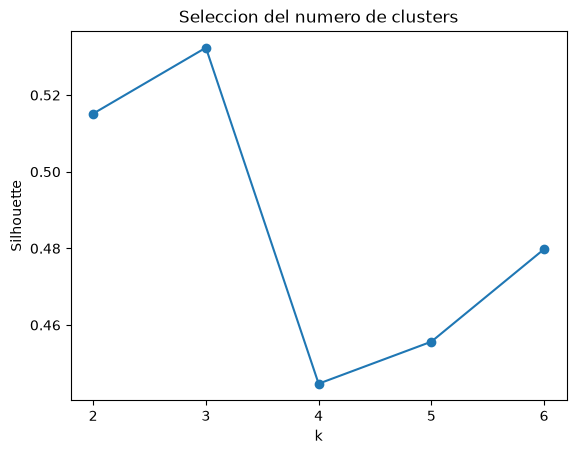

In [15]:
k_elegido = int(resultados.loc[resultados["silhouette"].idxmax(), "k"])
modelo = modelos[k_elegido]
etiquetas = modelo.labels_
print(f"Se elige k={k_elegido}: mayor Silhouette entre los valores evaluados.")
resultados.plot(x="k", y="silhouette", marker="o", legend=False)

plt.xticks(resultados["k"])
plt.ylabel("Silhouette")
plt.title("Seleccion del numero de clusters")
plt.show()

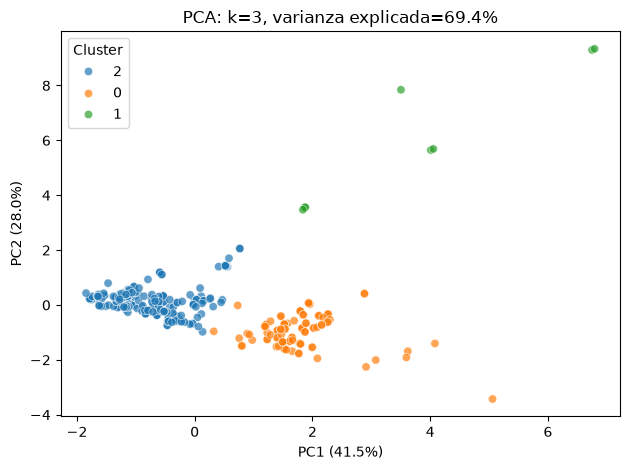

In [16]:
pca = PCA(n_components=2)
proyeccion = pca.fit_transform(X_escalado)
varianza = pca.explained_variance_ratio_ * 100
sns.scatterplot(x=proyeccion[:, 0], y=proyeccion[:, 1], hue=etiquetas.astype(str), palette="tab10", alpha=.7)
plt.xlabel(f"PC1 ({varianza[0]:.1f}%)")
plt.ylabel(f"PC2 ({varianza[1]:.1f}%)")
plt.title(f"PCA: k={k_elegido}, varianza explicada={varianza.sum():.1f}%")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

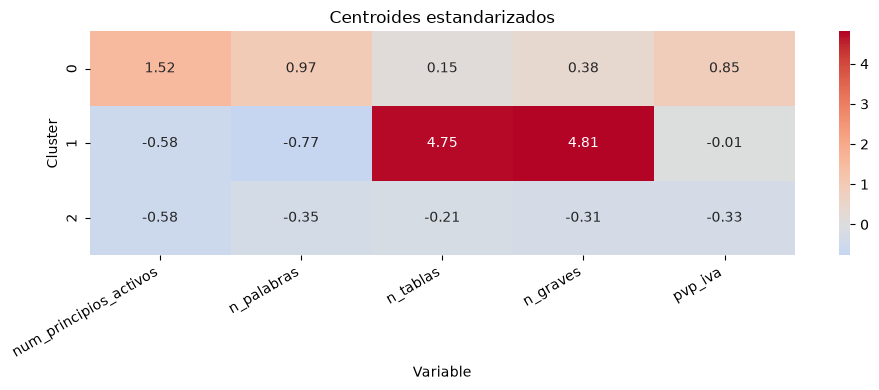

In [17]:
centroides = pd.DataFrame(modelo.cluster_centers_, columns=variables)
plt.figure(figsize=(10, 4))
sns.heatmap(centroides, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.xlabel("Variable")
plt.ylabel("Cluster")
plt.title("Centroides estandarizados")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [18]:
grupos = df.assign(cluster=etiquetas).groupby("cluster")
resumen = grupos[variables].mean()
resumen.insert(0, "tamano", grupos.size())
display(resumen.round(2))

,tamano,num_principios_activos,n_palabras,n_tablas,n_graves,pvp_iva
cluster,,,,,,
0,108,2.0,1448.78,3.74,14.99,39.79
1,9,1.0,570.44,26.22,66.67,22.13
2,275,1.0,782.35,1.98,7.02,15.38


Interpretacion descriptiva de los grupos (medias en las unidades originales):

- **Cluster 0: dos principios activos y mayor precio medio** (108 filas). Tiene 2 principios activos, unas 1449 palabras y un precio medio de 39,79.
- **Cluster 1: mayor numero de tablas y mayor n_graves** (9 filas). Destaca por unas 26,22 tablas y un valor medio de n_graves de 66,67. Es un grupo pequeno que conviene interpretar con cautela.
- **Cluster 2: un principio activo y menor precio medio** (275 filas). Tiene 1 principio activo, unas 782 palabras y un precio medio de 15,38.

Estos nombres describen los datos; no representan categorias clinicas. El mapa de calor compara cada centro con la media global en unidades de desviacion tipica. El PCA solo sirve para visualizar: K-Means y Silhouette utilizan las cinco variables escaladas.

In [ ]:
# CSV con los datos limpios
df_salida = df.copy()
df_salida["cluster"] = etiquetas
df_salida.to_csv(ruta.with_name("datos_clusters.csv"), index=False)

# CSV con los datos completos
completos = pd.read_csv(ruta.with_name("datos_completos.csv"), dtype={"nregistro": str})
completos["cluster"] = etiquetas
completos.to_csv(ruta.with_name("datos_completos_clusters.csv"), index=False)